# 2. PD model

Builds the probability of default (PD) model and its scorecard.

**Input:** `data/loan_data.pkl`.  
**Output:** PD predictions for each loan and the scorecard.

**2.1 Load the data  
2.2 Target and inputs  
2.3 Train/test split  
2.4 Prepare the inputs  
2.5 Model  
2.6 Evaluation  
2.7 Scorecard  
2.8 Save**

## 2.1 Load the data

We read `loan_data.pkl`, the table created in notebook 01, and check that it is the same table: the number of rows and columns and the default rate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
data_dir = '../data'  # relative to the notebooks folder

In [2]:
loan_data = pd.read_pickle(f'{data_dir}/loan_data.pkl')
loan_data.shape
# Expected output: (244967, 31)

(244967, 31)

In [3]:
loan_data['default'].mean()
# Expected output ~ 0.0575

np.float64(0.057493458302546874)

In [4]:
#loan_data.head()

## 2.2 Target and inputs

**Target.** The target is `default`: 1 if the loan defaulted, 0 otherwise. The model estimates the probability of default, PD = P(`default` = 1).

**Inputs.** The inputs are the loan and borrower characteristics known at origination. We exclude the following columns:

| Column | Reason |
|---|---|
| `default` | The target. |
| `loan_id` | Identifier of the loan; it does not describe the loan. |
| `zero_balance_code`, `zero_balance_removal_upb`, `actual_loss` | Known only when the loan closes, so they would leak the outcome. They are used in the LGD and EAD models. |
| `vintage`, `first_payment_date` | They identify the origination period. The model would learn the economic conditions of a period, not a characteristic of the borrower, and this does not carry over to new loans. |
| `maturity_date` | Equals `first_payment_date` plus `orig_loan_term`. It adds no information beyond the loan term. |
| `pre_harp_loan_id` | Identifier of the refinanced loan, filled only for HARP loans. The indicator `harp_indicator` already contains this information. |

In [5]:
input_cols = ['credit_score', 'first_time_homebuyer', 'msa', 'mi_pct', 'num_units',
              'occupancy_status', 'cltv', 'dti', 'orig_upb', 'ltv', 'int_rate',
              'channel', 'prepay_penalty', 'property_state', 'property_type',
              'postal_code', 'loan_purpose', 'orig_loan_term', 'num_borrowers',
              'seller_name', 'super_conforming', 'harp_indicator']
# The columns we keep as inputs

len(input_cols)

22

In [6]:
loan_data_inputs = loan_data[input_cols].copy()
loan_data_inputs.shape
#loan_data_inputs.head()

(244967, 22)

In [7]:
loan_data_targets = loan_data['default'].copy()
loan_data_targets.shape
#loan_data_targets.head()

(244967,)

In [8]:
loan_data_targets.mean()
# Expected output ~ 0.0575

np.float64(0.057493458302546874)

## 2.3 Train/test split

We split the loans randomly into a training set (80%) and a test set (20%). The model is fitted on the training set only. The test set is used once, at the end, to evaluate the model on loans it has not seen. The split is stratified by `default`, so both sets have the same default rate. The random seed is fixed so that the split is reproducible.

We split before preparing the inputs, so that nothing learned from the data in the next sections uses the test set.

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
loan_data_inputs_train, loan_data_inputs_test, loan_data_targets_train, loan_data_targets_test = train_test_split(
    loan_data_inputs, loan_data_targets, test_size = 0.2, random_state = 42, stratify = loan_data_targets)
# We split the data

In [11]:
print(loan_data_inputs_train.shape, loan_data_inputs_test.shape)
print(loan_data_targets_train.shape, loan_data_targets_test.shape)
print(loan_data_targets_train.mean(), loan_data_targets_test.mean())

(195973, 22) (48994, 22)
(195973,) (48994,)
0.05749261377842866 0.05749683634730783


## 2.4 Prepare the inputs

All quantities learned from the data in this section (bins, weights of evidence) are computed on the training set only and then applied to the test set.

### 2.4.1 Missing values

We focus on the inputs with missing values. A scoring model must give a score to every loan, so we cannot drop loans with missing values; we have to handle them. For each variable we look at two quantities:

1. the number of loans with a missing value,
2. the default rate of these loans compared with the default rate of the loans without a missing value.

If the group of missing values is small, it cannot support a category of its own and is merged with a similar one. If the group is large, we further look at the default rates. If the default rates of the two groups differ enough, we consider the missing value to be informative and it forms a separate category. Otherwise, it is merged with a similar group.

In [12]:
df_inputs_prepr = loan_data_inputs_train.copy()
df_targets_prepr = loan_data_targets_train.copy()

In [13]:
cols_with_nulls = []
num_of_nulls = []

for col in input_cols:
    if df_inputs_prepr[col].isnull().sum() != 0:
        cols_with_nulls.append(col)
        num_of_nulls.append(df_inputs_prepr[col].isnull().sum())
        
default_rate_nulls = []
default_rate_notnulls = []

for col in cols_with_nulls:
    a = df_targets_prepr[df_inputs_prepr[col].isnull()].mean()
    b = df_targets_prepr[~df_inputs_prepr[col].isnull()].mean()
    default_rate_nulls.append(a)
    default_rate_notnulls.append(b)

missing_summary = pd.DataFrame({'num_of_nulls' : num_of_nulls, 
                                'default_rate_nulls' : default_rate_nulls,
                                'default_rate_notnulls' : default_rate_notnulls}, 
                                index = cols_with_nulls)
missing_summary

,num_of_nulls,default_rate_nulls,default_rate_notnulls
credit_score,124,0.048387,0.057498
first_time_homebuyer,44,0.000000,0.057506
msa,37590,0.052807,0.058605
mi_pct,2,0.000000,0.057493
cltv,14,0.000000,0.057497
dti,7973,0.051047,0.057766
ltv,13,0.000000,0.057496
property_type,1,0.000000,0.057493
postal_code,1,0.000000,0.057493
num_borrowers,65,0.000000,0.057512


**Remark.** 10 inputs have missing values in the training set.

- `msa` (19% of the loans): a missing value means that the property is outside a metropolitan area (or the area is unknown). This is information about the property, so the missing values form a separate category, regardless of the default rates.
- `dti` (4% of the loans): the default rate of the loans with a missing value (5.1%) is close to that of the other loans (5.8%) and the group is a small part of the sample, so it does not form a category of its own.
- The other 8 variables have at most 124 loans with missing values. These groups are too small to form a category of their own.

For these nine variables, the loans with missing values are merged into one of the other categories when we group the values (sections 2.4.2 and 2.4.3).

### 2.4.2 Discrete variables

For a discrete variable we group the loans by category. A *good* loan is a loan without default (`default` = 0) and a *bad* loan is a loan with default (`default` = 1). For the category $i$, let $n_{\text{good}}(i)$ and $n_{\text{bad}}(i)$ be the number of good and bad loans in it, respectively. Also, let $N_{\text{good}}$ and $N_{\text{bad}}$ be the number of good and bad loans in the whole training set, respectively.

The **weight of evidence** (WoE) of the category $i$ is defined by

$$\text{WoE}(i) = \ln \left( \frac{n_{\text{good}}(i) / N_{\text{good}}}{n_{\text{bad}}(i) / N_{\text{bad}}} \right).$$

It compares the share of all good loans that fall in the category with the share of all bad loans that fall in it.

- $\text{WoE}(i) > 0$: the category contains a larger share of the good loans than of the bad loans. It is safer than the average.
- $\text{WoE}(i) < 0$: the category contains a larger share of the bad loans. It is riskier than the average.
- $\text{WoE}(i) = 0$: the category does not separate good from bad loans.

Equivalently, $\text{WoE}$ is the logarithm of the ratio between the odds good:bad in the category, $n_{\text{good}}(i) / n_{\text{bad}}(i)$, and the odds in the whole sample, $N_{\text{good}} / N_{\text{bad}}$. It is undefined when a category has no good or no bad loans.

The **information value** (IV) of the variable is defined by

$$\text{IV} = \sum_i \left( \frac{n_{\text{good}}(i)}{N_{\text{good}}} - \frac{n_{\text{bad}}(i)}{N_{\text{bad}}} \right) \text{WoE}(i)$$

where the sum is taken over all categories of the variable.

**Remarks on the formula.**

- We want to compare the distribution of the variable among the good loans with its distribution among the bad loans, so in each category we subtract: *share of good loans − share of bad loans*.
- The logarithm $\ln\frac{n_{\text{good}}(i)/N_{\text{good}}}{n_{\text{bad}}(i)/N_{\text{bad}}}$ is the weight of evidence. It measures the (logarithmic) relative difference between the two shares. It is $0$ if the shares are equal, positive if the category has a larger share of good loans and negative if it has a larger share of bad loans.
- The relative difference matters: the same absolute gap is more informative in a small category than in a large one. *E.g. shares $10\%$ and $5\%$: $0.05\cdot\ln 2\approx 0.035$; shares $50\%$ and $45\%$: $0.05\cdot\ln\frac{0.50}{0.45}\approx 0.005$.*
- Thus the IV is the sum, over all categories of the variable, of the differences of the shares weighted by their relative difference.
- The factors $\left(\frac{n_{\text{good}}(i)}{N_{\text{good}}}-\frac{n_{\text{bad}}(i)}{N_{\text{bad}}}\right)$ and $\text{WoE}(i)$ always have the same sign, so every term is non-negative and $\text{IV}\ge 0$. It is $0$ exactly when the two distributions coincide, that is, when the variable does not separate good from bad loans.

**Procedure.** We apply the same steps to each discrete variable:

1. **Table.** The function `woe_discrete` returns, for each category, the number of loans, the default rate, the weight of evidence (WoE), the differences of the default rate and of the WoE between consecutive categories (after sorting by WoE), and the information value (IV) of the variable.
2. **Plot.** The function `plot_by_woe` shows the WoE of the categories, sorted from the riskiest to the safest.
3. **Grouping.** We merge values that cannot be told apart into categories, so that every category is large enough to give a reliable default rate and the categories differ clearly in risk. We merge:
    - values with less than 5% of the loans, or with no or very few defaults,
    - consecutive values with a small difference in WoE,
    - the loans with a missing value, as decided in section 2.4.1.


    Merged values must also make sense together, i.e. describe similar situations and not only have close WoE by chance. For ordinal variables (e.g. `num_units`, `num_borrowers`), the WoE of the categories should be monotonic, as far as possible; for nominal variables (e.g. `channel`, `property_state`) the order of the values is arbitrary and this does not apply.
4. **Dummy variables.** Each final category becomes a dummy variable (1 if the loan belongs to the category, 0 otherwise). One category of each variable is left out as the reference category: the dummies of a variable sum to 1, the intercept column, so including all of them would cause perfect multicollinearity. As reference category we choose the category with the lowest WoE (the riskiest one), so that every coefficient is interpreted relative to the riskiest category of its variable.
5. **Selection.** A variable whose information value is below $0.02$ is considered not predictive and is excluded from the model. The usual rule of thumb is: $\text{IV} < 0.02$ not predictive, $0.02$–$0.1$ weak, $0.1$–$0.3$ medium, $0.3$–$0.5$ strong, and $\text{IV} > 0.5$ suspiciously strong (possible leakage of information from the target). Merging categories never increases the IV (this follows from the log-sum inequality, a consequence of Jensen's inequality). Hence, if the IV of the variable is below 0.02 before merging, it is also below 0.02 after any merge, and we drop the variable. Otherwise, we merge the categories and compute the IV again on the final categories.

All tables and groupings are computed on the training set only.

In [14]:
def woe_discrete(df, variable_name, targets):
    data = pd.concat([df[variable_name], targets.rename('default')], axis = 1)
    table = data.groupby(variable_name, dropna = False).agg(n_obs = ('default', 'count'),
                                                           n_bad = ('default', 'sum'))
    table['n_good'] = table['n_obs'] - table['n_bad']
    table['prop_n_obs'] = table['n_obs'] / table['n_obs'].sum()
    table['prop_n_bad'] = table['n_bad'] / table['n_bad'].sum()
    table['prop_n_good'] = table['n_good'] / table['n_good'].sum()
    table['WoE'] = np.log(table['prop_n_good'] / table['prop_n_bad'])
    table = table.sort_values('WoE').reset_index()
    table['diff_WoE'] = table['WoE'].diff().abs()
    table['default_rate'] = table['n_bad'] / table['n_obs']
    table['diff_default_rate'] = table['default_rate'].diff().abs()
    table['IV'] = ((table['prop_n_good'] - table['prop_n_bad']) * table['WoE']).sum()
    return table

In [15]:
def plot_by_woe(table, rotation = 0):
    x = table.iloc[:, 0].fillna('missing').astype(str)
    plt.figure(figsize = (10, 4))
    plt.plot(x, table['WoE'], marker = 'o', linestyle = '--', color = 'k')
    plt.xlabel(table.columns[0])
    plt.ylabel('Weight of evidence')
    plt.title('Weight of evidence by ' + table.columns[0])
    plt.xticks(rotation = rotation)
    plt.show()

In [16]:
ref_categories = {}
# For each discrete input variable, we store the reference category

#### 1. `first_time_homebuyer`

In [17]:
first_time_homebuyer_table = woe_discrete(df_inputs_prepr, 'first_time_homebuyer', df_targets_prepr)
first_time_homebuyer_table

,first_time_homebuyer,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,Y,19129,1347,17782,0.097610,0.119553,0.096272,-0.216580,NaN,0.070417,NaN,inf
1,N,176800,9920,166880,0.902165,0.880447,0.903490,0.025835,0.242415,0.056109,0.014308,inf
2,NaN,44,0,44,0.000225,0.000000,0.000238,inf,inf,0.000000,0.056109,inf


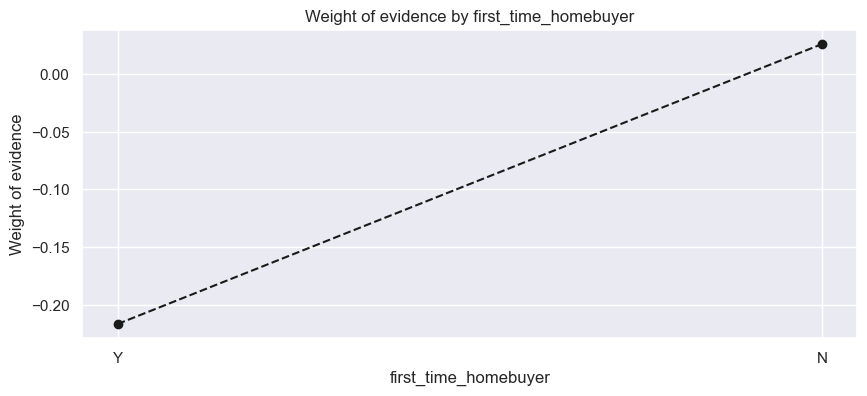

In [18]:
plot_by_woe(first_time_homebuyer_table)

- First-time homebuyers (`Y`) default more often (7.0%) than the others (5.6%), so the two categories are kept separate.
- The 44 loans with a missing value are too few to form a category and are merged with the largest one, `N`, because this changes the category the least.

In [19]:
# We set missing values as `N`.
df_inputs_prepr['first_time_homebuyer'] = df_inputs_prepr['first_time_homebuyer'].fillna('N')

In [20]:
# We look again at the IV
first_time_homebuyer_table = woe_discrete(df_inputs_prepr, 'first_time_homebuyer', df_targets_prepr)
first_time_homebuyer_table

,first_time_homebuyer,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,Y,19129,1347,17782,0.09761,0.119553,0.096272,-0.216580,NaN,0.070417,NaN,0.00565
1,N,176844,9920,166924,0.90239,0.880447,0.903728,0.026098,0.242679,0.056095,0.014322,0.00565


**Remark.** Since after merging $\text{IV} \approx 0.006$, below the threshold of $0.02$, the variable `first_time_homebuyer` is excluded from the model. We create no dummy variables for it and add no entry to `ref_categories`.

#### 2. `num_units`

In [21]:
num_units_table = woe_discrete(df_inputs_prepr, 'num_units', df_targets_prepr)
num_units_table

,num_units,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,2.0,3040,246,2794,0.015512,0.021834,0.015127,-0.366989,NaN,0.080921,NaN,0.002706
1,3.0,486,35,451,0.002480,0.003106,0.002442,-0.240768,0.126221,0.072016,0.008905,0.002706
2,4.0,425,27,398,0.002169,0.002396,0.002155,-0.106272,0.134496,0.063529,0.008487,0.002706
3,1.0,192022,10959,181063,0.979839,0.972664,0.980277,0.007797,0.114069,0.057072,0.006458,0.002706


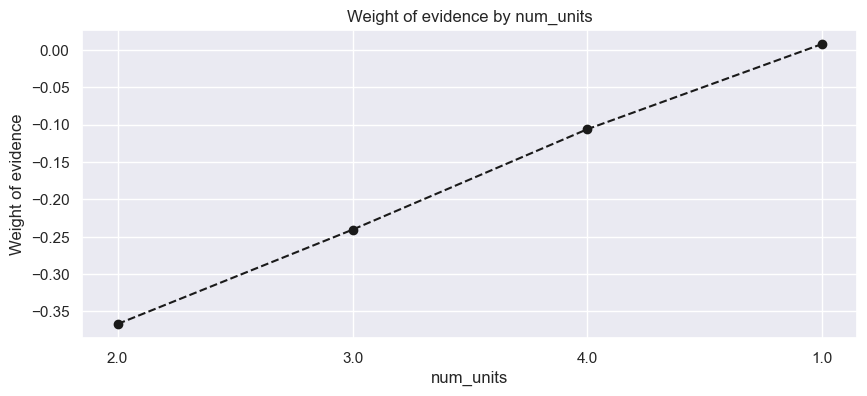

In [22]:
plot_by_woe(num_units_table)

**Remark.** Since $\text{IV} \approx 0.003$, below the threshold of $0.02$, the variable `num_units` is excluded from the model. We create no dummy variables for it and add no entry to `ref_categories`.

#### 3. `occupancy_status`

In [23]:
occupancy_status_table = woe_discrete(df_inputs_prepr, 'occupancy_status', df_targets_prepr)
occupancy_status_table

,occupancy_status,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,I,10278,935,9343,0.052446,0.082986,0.050583,-0.495051,NaN,0.090971,NaN,0.01722
1,S,9960,571,9389,0.050823,0.050679,0.050832,0.003018,0.498069,0.057329,0.033642,0.01722
2,P,175735,9761,165974,0.896731,0.866335,0.898585,0.036549,0.033531,0.055544,0.001785,0.01722


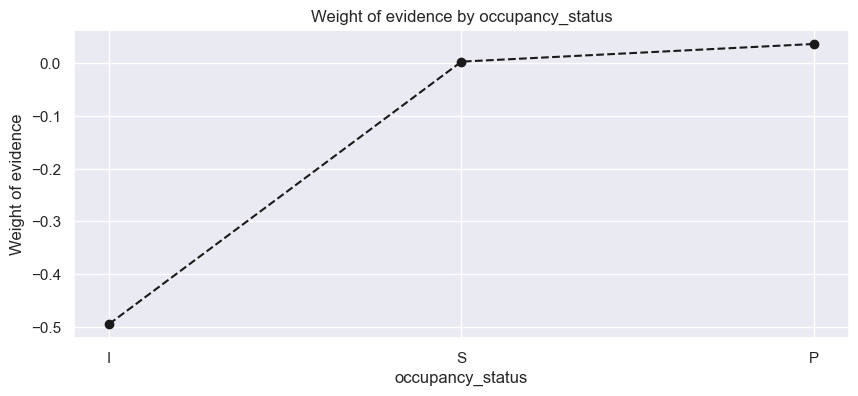

In [24]:
plot_by_woe(occupancy_status_table)

**Remark.** There are no missing values. The IV of the two categories is $\approx 0.001 < 0.02$, and since merging categories never increases the IV, it stays below $0.02$ for any grouping. Hence `prepay_penalty` is dropped from the model. We create no dummy variables for it and add no entry to `ref_categories`.

#### 4. `channel`

In [25]:
channel_table = woe_discrete(df_inputs_prepr, 'channel', df_targets_prepr)
channel_table

,channel,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,T,71662,6296,65366,0.365673,0.558800,0.353892,-0.456800,NaN,0.087857,NaN,0.204479
1,R,95317,4230,91087,0.486378,0.375433,0.493146,0.272726,0.729525,0.044378,0.043479,0.204479
2,B,11004,359,10645,0.056151,0.031863,0.057632,0.592636,0.319910,0.032625,0.011754,0.204479
3,C,17990,382,17608,0.091798,0.033904,0.095330,1.033801,0.441165,0.021234,0.011390,0.204479


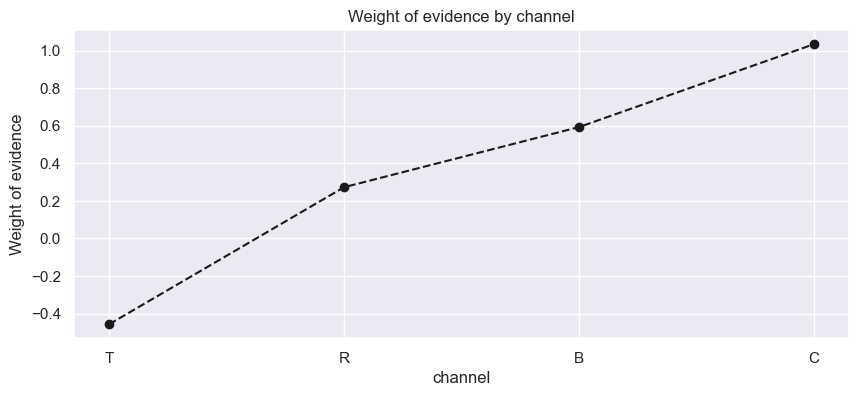

In [26]:
plot_by_woe(channel_table)

**Remark.** There are no missing values. All four categories are large and their default rates differ clearly, so no categories are merged. $\text{IV} \approx 0.204 > 0.02$, hence `channel` is kept. The reference category is `T`, the one with the lowest WoE.

In [27]:
# Add the first reference category on the dictionary
ref_categories['channel'] = 'channel:T'

In [28]:
# Create the dummies
categories = ['T', 'R', 'B', 'C']
for category in categories:
    df_inputs_prepr[f'channel:{category}'] = np.where((df_inputs_prepr['channel'] == category), 1, 0)

In [29]:
df_inputs_prepr[['channel:T', 'channel:R', 'channel:B', 'channel:C']].sum(axis = 1).value_counts()
# Expected output: 1 for all 195973 loans

1    195973
Name: count, dtype: int64

#### 5. `prepay_penalty`

In [30]:
prepay_penalty_table = woe_discrete(df_inputs_prepr, 'prepay_penalty', df_targets_prepr)
prepay_penalty_table

,prepay_penalty,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,Y,192,23,169,0.00098,0.002041,0.000915,-0.802483,NaN,0.119792,NaN,0.000905
1,N,195781,11244,184537,0.99902,0.997959,0.999085,0.001128,0.803611,0.057432,0.06236,0.000905


**Remark.** There are no missing values. SInce $\text{IV} \approx 0.001 < 0.02$, `prepay_penalty` is dropped from the model. We create no dummy variables for it and add no entry to `ref_categories`.

#### 6. `property_state`

In [31]:
property_state_table = woe_discrete(df_inputs_prepr, 'property_state', df_targets_prepr)
property_state_table

,property_state,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,NV,1703,321,1382,0.008690,0.028490,0.007482,-1.337041,NaN,0.188491,NaN,inf
1,FL,10923,1695,9228,0.055737,0.150439,0.049960,-1.102328,0.234714,0.155177,0.033314,inf
2,AZ,5336,756,4580,0.027228,0.067099,0.024796,-0.995474,0.106853,0.141679,0.013498,inf
3,MI,6598,604,5994,0.033668,0.053608,0.032452,-0.501947,0.493527,0.091543,0.050136,inf
4,GA,5947,492,5455,0.030346,0.043667,0.029533,-0.391078,0.110869,0.082731,0.008812,inf
5,RI,700,57,643,0.003572,0.005059,0.003481,-0.373794,0.017284,0.081429,0.001302,inf
6,MS,838,57,781,0.004276,0.005059,0.004228,-0.179363,0.194430,0.068019,0.013409,inf
7,ID,1485,96,1389,0.007578,0.008520,0.007520,-0.124896,0.054467,0.064646,0.003373,inf
8,IL,10743,671,10072,0.054819,0.059554,0.054530,-0.088142,0.036754,0.062459,0.002187,inf
9,CA,18247,1137,17110,0.093110,0.100914,0.092634,-0.085617,0.002524,0.062312,0.000148,inf


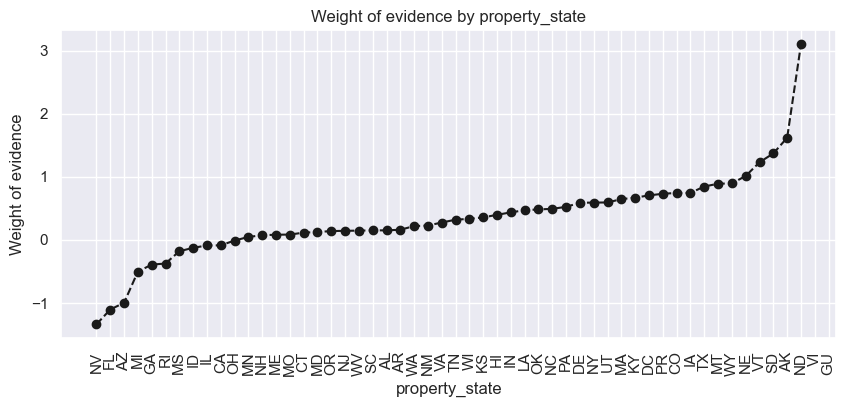

In [32]:
plot_by_woe(property_state_table, rotation = 90)

`property_state` has 54 values (states), and only four of them contain more than 5% of the loans. Moreover, `VI` and `GU` contain no defaults, so their WoE is not defined and the IV cannot be computed before merging. We therefore merge the states before computing the IV. The categories are sets of consecutive states in the order of the WoE, so that states with a similar risk are merged. Each category contains at least 5% of the loans, so that its default rate is reliable. The boundaries are placed where the WoE jumps and, where it grows gradually, as soon as the category reaches 5% of the loans. `VI` and `GU` are merged into the category with the highest WoE.

In [33]:
property_state_table['cum_prop_n_obs'] = property_state_table['prop_n_obs'].cumsum()
property_state_table[['property_state', 'prop_n_obs', 'cum_prop_n_obs', 'WoE', 'diff_WoE']]

,property_state,prop_n_obs,cum_prop_n_obs,WoE,diff_WoE
0,NV,0.008690,0.008690,-1.337041,NaN
1,FL,0.055737,0.064427,-1.102328,0.234714
2,AZ,0.027228,0.091655,-0.995474,0.106853
3,MI,0.033668,0.125323,-0.501947,0.493527
4,GA,0.030346,0.155669,-0.391078,0.110869
5,RI,0.003572,0.159241,-0.373794,0.017284
6,MS,0.004276,0.163517,-0.179363,0.194430
7,ID,0.007578,0.171095,-0.124896,0.054467
8,IL,0.054819,0.225914,-0.088142,0.036754
9,CA,0.093110,0.319024,-0.085617,0.002524


- First category: `NV`, `FL`, `AZ`. Their WoE is similar (from $-1.34$ to $-1.00$) and there is a clear gap between `AZ` and the next value, `MI`.
- Second category: `MI`, `GA`, `RI`. Same reason: similar WoE (from $-0.50$ to $-0.37$) and a gap before the next value, `MS`.
- `VI` and `GU` are too small and contain no defaults, so their WoE is not defined. We merge them with the last category, when we form it.
- We leave these eight states out of the plot below, to see the differences between the remaining ones more clearly. This only affects the plot; the data are not changed.

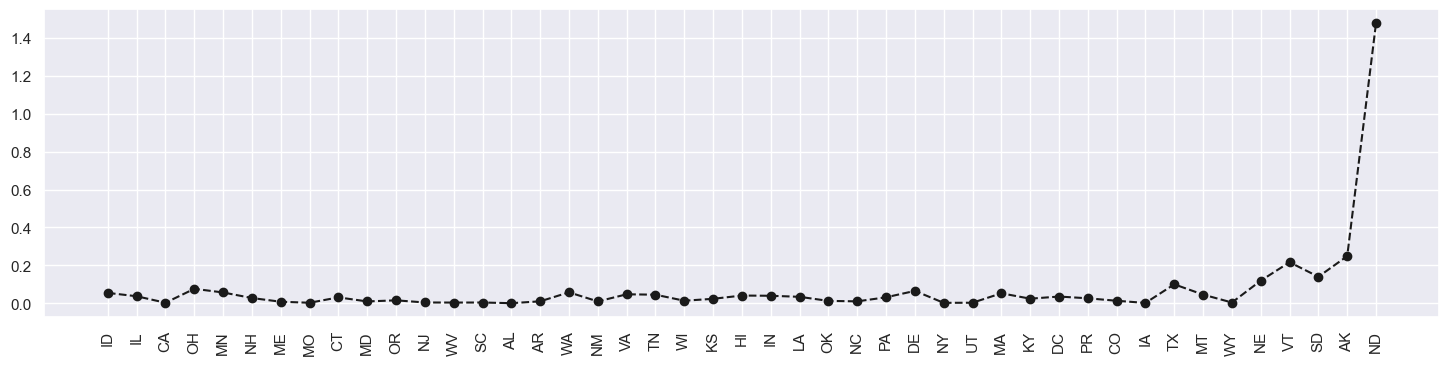

In [34]:
middle = property_state_table.iloc[6:52]
# The states between the first two categories and the last (VI, GU)

plt.figure(figsize = (18, 4))
plt.plot(middle['property_state'].iloc[1:], middle['diff_WoE'].iloc[1:], marker = 'o', linestyle = '--', color = 'k')
plt.xticks(rotation = 90)
plt.show()

Final categories:

| Category | States | Loans |
|---|---|---|
| 1 | `NV`, `FL`, `AZ` | 9.2% |
| 2 | `MI`, `GA`, `RI` | 6.8% |
| 3 | `MS`, `ID`, `IL`, `CA` | 16.0% |
| 4 | `OH`, `MN`, `NH`, `ME`, `MO`, `CT`, `MD`, `OR`, `NJ`, `WV`, `SC`, `AL`, `AR` | 22.1% |
| 5 | `WA`, `NM`, `VA`, `TN`, `WI`, `KS`, `HI`, `IN`, `LA`, `OK`, `NC`, `PA`, `DE` | 24.9% |
| 6 | `NY`, `UT`, `MA`, `KY`, `DC`, `PR`, `CO`, `IA` | 12.9% |
| 7 | `TX`, `MT`, `WY`, `NE`, `VT`, `SD`, `AK`, `ND`, `VI`, `GU` | 8.1% |

- In categories 1–6 the WoE of the states differs by at most $0.37$. The boundaries between categories 1 and 2, and between 2 and 3, are at clear jumps of the WoE. Elsewhere the WoE grows gradually and the boundaries are placed so that each category has at least 5% of the loans and the WoE inside it varies little.
- Category 7 contains the safest states. `NE`, `VT`, `SD`, `AK`, `ND`, `VI` and `GU` are too small (together 1.7% of the loans) and have too few defaults for a reliable WoE (`VI` and `GU` have none), so they are merged with `TX`, `MT` and `WY`.

In [35]:
# Create the dummies
property_state_groups = {
    1: ['NV', 'FL', 'AZ'],
    2: ['MI', 'GA', 'RI'],
    3: ['MS', 'ID', 'IL', 'CA'],
    4: ['OH', 'MN', 'NH', 'ME', 'MO', 'CT', 'MD', 'OR', 'NJ', 'WV', 'SC', 'AL', 'AR'],
    5: ['WA', 'NM', 'VA', 'TN', 'WI', 'KS', 'HI', 'IN', 'LA', 'OK', 'NC', 'PA', 'DE'],
    6: ['NY', 'UT', 'MA', 'KY', 'DC', 'PR', 'CO', 'IA'],
    7: ['TX', 'MT', 'WY', 'NE', 'VT', 'SD', 'AK', 'ND', 'VI', 'GU']}
# The categories of property_state, with the states they contain

for category, states in property_state_groups.items():
    df_inputs_prepr[f'property_state:{category}'] = np.where(df_inputs_prepr['property_state'].isin(states), 1, 0)

dummy_cols = [f'property_state:{i}' for i in range(1, 8)]
df_inputs_prepr[dummy_cols].sum(axis = 1).value_counts()
# Expected output: 1 for all 195973 loans

1    195973
Name: count, dtype: int64

In [36]:
# Check the IV
property_state_grouped = df_inputs_prepr[dummy_cols].idxmax(axis = 1).to_frame('property_state')
property_state_table_grouped = woe_discrete(property_state_grouped, 'property_state', df_targets_prepr)
property_state_table_grouped

,property_state,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,property_state:1,17962,2772,15190,0.091655,0.246028,0.082239,-1.095819,NaN,0.154326,NaN,0.31978
1,property_state:2,13245,1153,12092,0.067586,0.102334,0.065466,-0.446710,0.649109,0.087052,0.067274,0.31978
2,property_state:3,31313,1961,29352,0.159782,0.174048,0.158912,-0.090981,0.355729,0.062626,0.024426,0.31978
3,property_state:4,43224,2273,40951,0.220561,0.201740,0.221709,0.094388,0.185370,0.052587,0.010039,0.31978
4,property_state:5,48894,1955,46939,0.249494,0.173516,0.254128,0.381571,0.287183,0.039984,0.012602,0.31978
5,property_state:6,25374,780,24594,0.129477,0.069229,0.133152,0.654077,0.272505,0.030740,0.009244,0.31978
6,property_state:7,15961,373,15588,0.081445,0.033106,0.084394,0.935791,0.281714,0.023369,0.007371,0.31978


**Remark.** There are no missing values. The 54 states are merged into 7 categories (table above). After merging, $\text{IV} \approx 0.320 > 0.02$, and the WoE increases from category 1 to category 7. Hence `property_state` is kept. The reference category is category 1, the one with the lowest WoE.

In [37]:
ref_categories['property_state'] = 'property_state:1'
# Add the reference category

#### 7. `property_type`

In [38]:
property_type_table = woe_discrete(df_inputs_prepr, 'property_type', df_targets_prepr)
property_type_table

,property_type,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,MH,1824,223,1601,0.009307,0.019792,0.008668,-0.825675,NaN,0.122259,NaN,inf
1,CO,14688,1236,13452,0.074949,0.109701,0.072829,-0.409640,0.416035,0.084150,0.038108,inf
2,SF,148038,8192,139846,0.755400,0.727079,0.757128,0.040496,0.450136,0.055337,0.028813,inf
3,PU,30776,1604,29172,0.157042,0.142363,0.157937,0.103822,0.063325,0.052119,0.003219,inf
4,CP,646,12,634,0.003296,0.001065,0.003432,1.170255,1.066433,0.018576,0.033543,inf
5,NaN,1,0,1,0.000005,0.000000,0.000005,inf,inf,0.000000,0.018576,inf


Only one loan has a missing value, and it does not default, so it gives no information about the risk. We merge it with the largest category, `SF`, because this changes the category the least.

In [39]:
df_inputs_prepr['property_type'] = df_inputs_prepr['property_type'].fillna('SF')
property_type_table = woe_discrete(df_inputs_prepr, 'property_type', df_targets_prepr)
property_type_table

,property_type,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,MH,1824,223,1601,0.009307,0.019792,0.008668,-0.825675,NaN,0.122259,NaN,0.029894
1,CO,14688,1236,13452,0.074949,0.109701,0.072829,-0.409640,0.416035,0.084150,0.038108,0.029894
2,SF,148039,8192,139847,0.755405,0.727079,0.757133,0.040504,0.450143,0.055337,0.028814,0.029894
3,PU,30776,1604,29172,0.157042,0.142363,0.157937,0.103822,0.063318,0.052119,0.003218,0.029894
4,CP,646,12,634,0.003296,0.001065,0.003432,1.170255,1.066433,0.018576,0.033543,0.029894


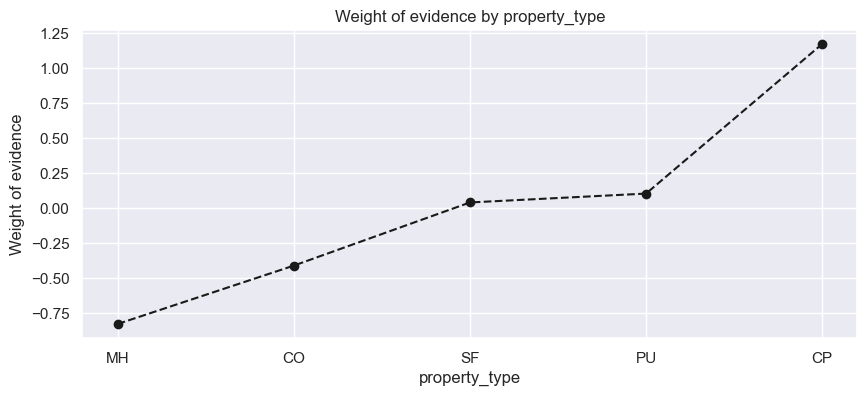

In [40]:
plot_by_woe(property_type_table)

- `MH` and `CO` are merged: both are riskier than average (WoE $-0.83$ and $-0.41$). Together they contain 8.4% of the loans.
- `SF` is the largest category (75.5% of the loans) and stays alone. It also contains the one loan with a missing value.
- `PU` and `CP` are merged: `CP` has only 0.3% of the loans and 12 defaults, so its default rate is unreliable. Together they contain 16.0% of the loans.

In [41]:
# Create the dummies
property_type_groups = {
    'MH_CO': ['MH', 'CO'],
    'SF': ['SF'],
    'PU_CP': ['PU', 'CP']}
# The categories of property_type, with the values they contain

for category, values in property_type_groups.items():
    df_inputs_prepr[f'property_type:{category}'] = np.where(df_inputs_prepr['property_type'].isin(values), 1, 0)

dummy_cols = [f'property_type:{category}' for category in property_type_groups]
df_inputs_prepr[dummy_cols].sum(axis = 1).value_counts()
# Expected output: 1 for all 195973 loans

1    195973
Name: count, dtype: int64

In [42]:
property_type_grouped = df_inputs_prepr[dummy_cols].idxmax(axis = 1).to_frame('property_type')
property_type_table_grouped = woe_discrete(property_type_grouped, 'property_type', df_targets_prepr)
property_type_table_grouped

,property_type,n_obs,n_bad,n_good,prop_n_obs,prop_n_bad,prop_n_good,WoE,diff_WoE,default_rate,diff_default_rate,IV
0,property_type:MH_CO,16512,1459,15053,0.084257,0.129493,0.081497,-0.463061,NaN,0.088360,NaN,0.025557
1,property_type:SF,148039,8192,139847,0.755405,0.727079,0.757133,0.040504,0.503565,0.055337,0.033023,0.025557
2,property_type:PU_CP,31422,1616,29806,0.160338,0.143428,0.161370,0.117868,0.077365,0.051429,0.003908,0.025557


**Remark.** After merging, $\text{IV} \approx 0.026 > 0.02$, so `property_type` is kept as a weak predictor. The WoE increases from `MH_CO` to `PU_CP`. The reference category is `MH_CO`, the one with the lowest WoE.

In [43]:
ref_categories['property_type'] = 'property_type:MH_CO'